<h1>Train — ConvNeXt-Tiny</h1>

Trains and evaluates ConvNeXt-Tiny using the tuned hyperparameters from `ARCH_HYPERPARAMS["convnext_tiny"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["convnext_tiny"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ConvNeXt-Tiny: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ConvNeXt-Tiny: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ConvNeXt-Tiny)
# ---------------------------------------------------------
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

model.avgpool = nn.AdaptiveMaxPool2d(1)

in_f = model.classifier[2].in_features
model.classifier[2] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
# criterion = FocalLoss(weight=class_weights_arch, gamma=2.0)  # parked for later -- see todo.txt

optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)

scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ConvNeXt-Tiny] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ConvNeXt-Tiny] Epoch   1/100 | LR: 9.93e-05 | train loss 0.9981 acc 0.580 | val loss 0.5929 acc 0.734 *


[ConvNeXt-Tiny] Epoch   2/100 | LR: 9.93e-05 | train loss 0.4744 acc 0.789 | val loss 0.5637 acc 0.765 *


[ConvNeXt-Tiny] Epoch   3/100 | LR: 9.93e-05 | train loss 0.3518 acc 0.843 | val loss 0.5418 acc 0.793 *


[ConvNeXt-Tiny] Epoch   4/100 | LR: 9.93e-05 | train loss 0.2775 acc 0.878 | val loss 0.3881 acc 0.867 *


...

[ConvNeXt-Tiny] Epoch  10/100 | LR: 9.93e-05 | train loss 0.1215 acc 0.947 | val loss 0.3957 acc 0.861


[ConvNeXt-Tiny] Epoch  11/100 | LR: 9.93e-05 | train loss 0.1029 acc 0.954 | val loss 0.5829 acc 0.836


[ConvNeXt-Tiny] Epoch  12/100 | LR: 9.93e-05 | train loss 0.0535 acc 0.978 | val loss 0.4281 acc 0.879


[ConvNeXt-Tiny] Epoch  13/100 | LR: 9.93e-05 | train loss 0.0967 acc 0.954 | val loss 0.4287 acc 0.885


[ConvNeXt-Tiny] Epoch  14/100 | LR: 9.93e-05 | train loss 0.0922 acc 0.966 | val loss 0.5738 acc 0.854

[ConvNeXt-Tiny] No val loss improvement for 10 epochs — stopping early at epoch 14.

[ConvNeXt-Tiny] Restored best checkpoint (val loss = 0.3881)


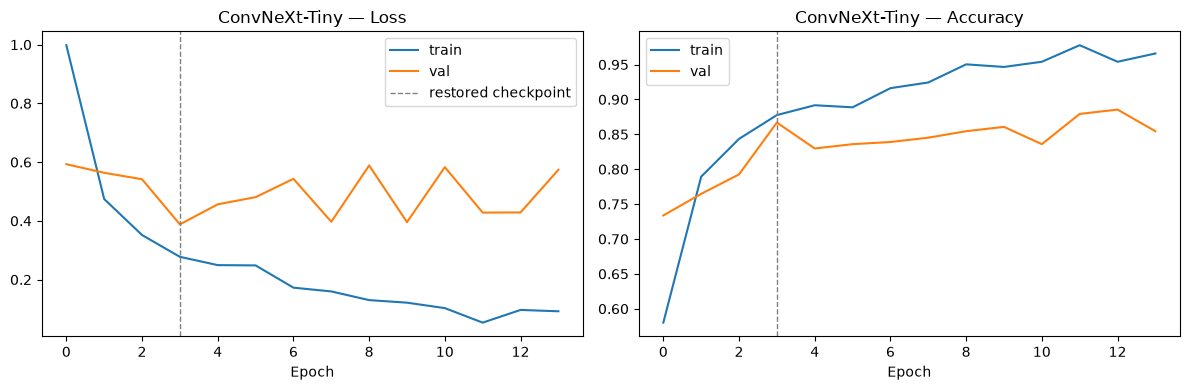

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ConvNeXt-Tiny", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ConvNeXt-Tiny")

## Evaluate on the test set

[ConvNeXt-Tiny] Test accuracy: 0.838


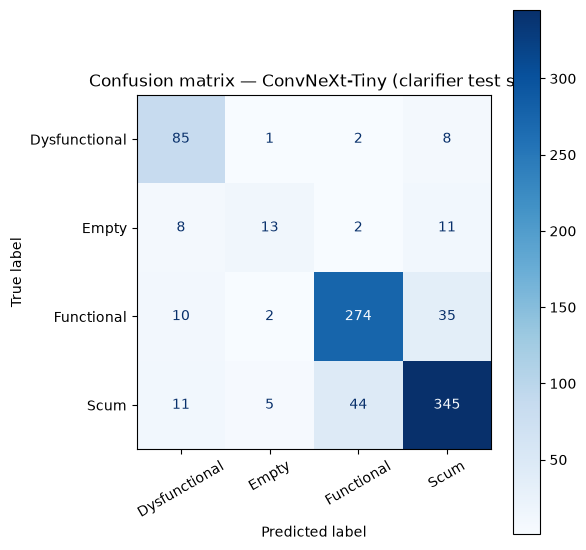

               precision    recall  f1-score   support

Dysfunctional      0.746     0.885     0.810        96
        Empty      0.619     0.382     0.473        34
   Functional      0.851     0.854     0.852       321
         Scum      0.865     0.852     0.858       405

     accuracy                          0.838       856
    macro avg      0.770     0.743     0.748       856
 weighted avg      0.836     0.838     0.835       856



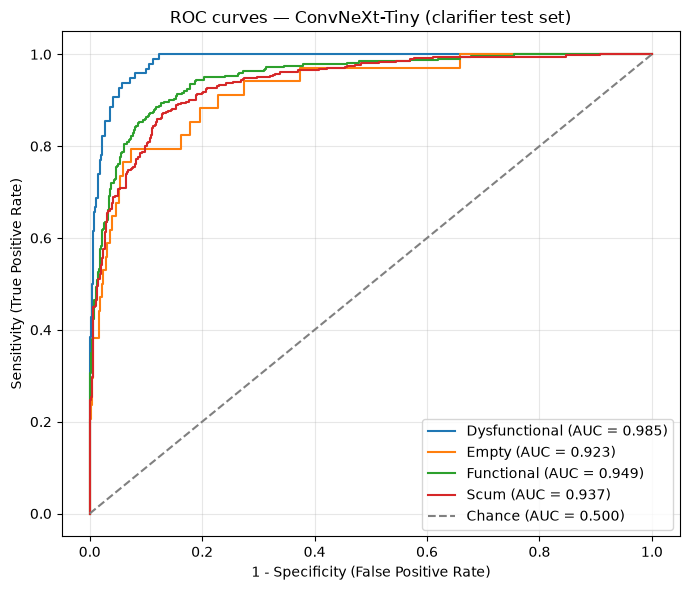

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.985
  Empty          : 0.923
  Functional     : 0.949
  Scum           : 0.937

Mean AUC (over 4/4 classes with test examples): 0.949


(np.float64(0.8376168224299065),
 {'Dysfunctional': 0.9851288377192983,
  'Empty': 0.9228567339344498,
  'Functional': 0.9494511893324017,
  'Scum': 0.9366291642714407})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ConvNeXt-Tiny", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("ConvNeXt-Tiny", "convnext_tiny")

Saved results to ../results/clarifier_aug/results_clarifier_convnext_tiny_chronological.pkl
Saved model weights to ../models/pad/clarifier_convnext_tiny_cnn.pt
